# vibrational.retrieval.hc

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.retrieval.hc')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "vibrational.retrieval.hc",
  "status": "recorded_results",
  "source_sha256": {
    "vibrational_ranked_examples_20261117.json": "b7e464aa11e85fdcae7245d987d92f272d6c1a5e47d697734df17d26731744e3"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "ZINCV2-ZINC000646741030",
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.15220004320144653,
        0.190755695104599,
        0.2037702202796936,
        0.1804114133119583,
        0.1386023461818695,
        0.10100352019071579,
        0.07402963191270828,
        0.05563068017363548
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.04284051060676575,
        0.0596662312746048,
        0.059223152697086334,
        0.04435715824365616,
        0.03070877492427826,
        0.02493642456829548,
        0.021241741254925728,
        0.01620982028543949
      ]
    },
    "nmr_h_shifts_ppm": {
      "length": 13,
      "first_values": [
        0.40027499198913574,
        0.70107501745224,
        3.4114749431610107,
        3.4215750694274902,
        3.694974899291992,
        3.7509748935699463,
        3.7543749809265137,
        3.904474973678589
      ]
    },
    "nmr_c_shifts_ppm": {
     

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | recall_at_1 | 1 |
| recorded sample | recorded model | mrr | 1 |
| recorded sample | recorded model | queries | 16 |
| recorded sample | recorded model | candidate_pool | 16 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## 预测／参考对照图

完整四模态协议适配合理。候选池检索／ITM 不等于开放结构生成；需扩大独立候选库验证。

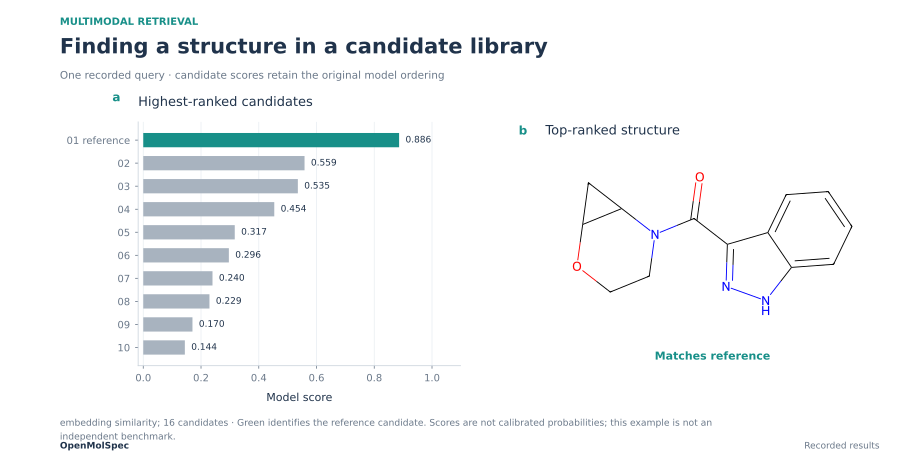

In [4]:
figure = render('vibrational.retrieval.hc', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/vibrational-retrieval-hc.md) · [Quick Start](../quickstart.md)
